# S&P 500 annualized returns since 2010 — with and without the top 10 companies

**Part 1** measures the S&P 500's annualized return (CAGR) from the first trading day of 2010 until the latest close, using the official index series from Yahoo Finance:
- `^GSPC` — price index (no dividends)
- `^SP500TR` — total return index (dividends reinvested)

**Part 2** removes the 10 largest companies and recomputes the same figures. Nobody publishes an "S&P 500 ex-top-10" series, so it is rebuilt from constituent data:
1. Take the current S&P 500 constituents (from Wikipedia) and their dividend-adjusted daily prices.
2. Estimate each stock's market cap as adjusted price × current shares outstanding.
3. Build a cap-weighted index from those, then build it again without the top 10 companies. Share classes are grouped by company, so GOOGL and GOOG count as one company (Alphabet).
4. Check the full rebuilt index against the real `^SP500TR` to see how much bias the method adds.

Two ways to pick the "top 10":
- **Static**: today's 10 largest companies, excluded for the whole period.
- **Annual rebalance**: at the start of each year, exclude that year's 10 largest (by estimated market cap).

The most reliable figure is the **spread** between the rebuilt full index and the rebuilt ex-top-10 index, since both carry the same biases (see the caveats at the end).

In [1]:
import io
import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

START = "2010-01-01"
pd.set_option("display.float_format", "{:.2%}".format)

def cagr(series: pd.Series) -> float:
    s = series.dropna()
    years = (s.index[-1] - s.index[0]).days / 365.25
    return (s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1

def calendar_returns(series: pd.Series) -> pd.Series:
    yearly = series.resample("YE").last()
    first = series.dropna().iloc[:1]
    out = pd.concat([first, yearly]).pct_change().dropna()
    out.index = out.index.year
    return out

## Part 1 — the S&P 500 index

In [2]:
idx = yf.download(["^GSPC", "^SP500TR"], start=START, auto_adjust=True, progress=False)["Close"].dropna()
start_date, end_date = idx.index[0], idx.index[-1]
years = (end_date - start_date).days / 365.25
print(f"Period: {start_date.date()} → {end_date.date()} ({years:.2f} years)")

summary_idx = pd.DataFrame({
    "Total return": idx.iloc[-1] / idx.iloc[0] - 1,
    "Annualized (CAGR)": idx.apply(cagr),
}).rename(index={"^GSPC": "S&P 500 (price)", "^SP500TR": "S&P 500 (total return)"})
summary_idx

Period: 2010-01-04 → 2026-10-05 (16.75 years)


,Total return,Annualized (CAGR)
Ticker,,
S&P 500 (price),586.14%,12.18%
S&P 500 (total return),833.94%,14.27%


In [3]:
annual_idx = pd.DataFrame({
    "Price": calendar_returns(idx["^GSPC"]),
    "Total return": calendar_returns(idx["^SP500TR"]),
})
annual_idx.index.name = "Year"
annual_idx.loc[end_date.year] = annual_idx.loc[end_date.year]  # current year is YTD
annual_idx.rename(index={end_date.year: f"{end_date.year} (YTD)"})

,Price,Total return
Year,,
2010,11.00%,13.24%
2011,-0.00%,2.11%
2012,13.41%,16.00%
2013,29.60%,32.39%
2014,11.39%,13.69%
2015,-0.73%,1.38%
2016,9.54%,11.96%
2017,19.42%,21.83%
2018,-6.24%,-4.38%


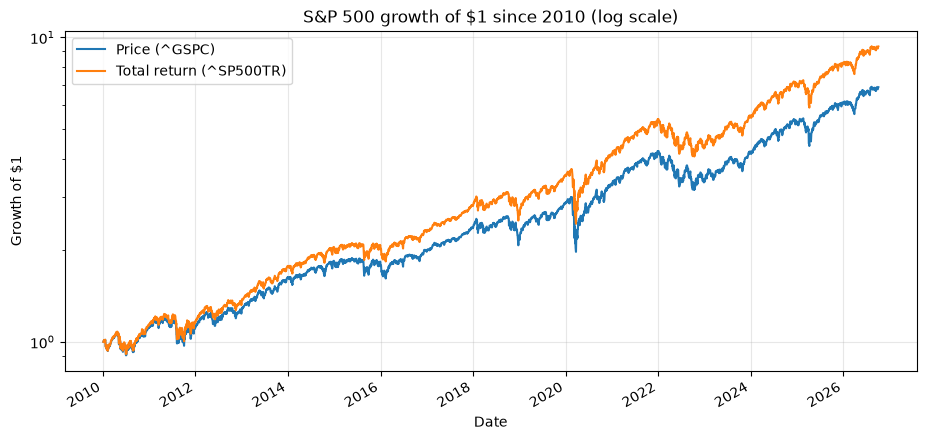

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
(idx / idx.iloc[0]).plot(ax=ax, logy=True)
ax.set_title("S&P 500 growth of $1 since 2010 (log scale)")
ax.set_ylabel("Growth of $1"); ax.grid(alpha=.3)
ax.legend(["Price (^GSPC)", "Total return (^SP500TR)"]); plt.show()

## Part 2 — S&P 500 without the top 10 companies
### 2a. Constituents, prices and shares outstanding

In [5]:
import warnings
warnings.filterwarnings("ignore")
html = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
                    headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
const = pd.read_html(io.StringIO(html))[0][["Symbol", "Security", "CIK"]]
const["yf"] = const["Symbol"].str.replace(".", "-", regex=False)  # BRK.B -> BRK-B
print(len(const), "tickers,", const["CIK"].nunique(), "distinct companies")

503 tickers, 500 distinct companies


In [6]:
def download(tickers):
    raw = yf.download(tickers, start=START, auto_adjust=False, progress=False, threads=True)
    return raw["Adj Close"], raw["Close"], raw["Volume"]

adj, close, volume = download(const["yf"].tolist())
for attempt in range(3):  # Yahoo occasionally drops a few tickers; retry them
    failed = [t for t in const["yf"] if t not in adj or adj[t].isna().all()]
    if not failed: break
    a, c, v = download(failed)
    adj[failed], close[failed], volume[failed] = a[failed], c[failed], v[failed]
adj, close = adj.reindex(idx.index), close.reindex(idx.index)
print("Tickers without price data:", [t for t in const["yf"] if adj[t].isna().all()])

Tickers without price data: []


Companies with several share classes (Alphabet, Fox, News Corp) report the **whole company's** share count on every class. To avoid double counting, keep one ticker per company: the one with the longest history, and the more liquid one on ties.

In [7]:
const["history"] = const["yf"].map(adj.notna().sum())
const["liquidity"] = const["yf"].map(volume.iloc[-60:].mean())
keep = (const.sort_values(["history", "liquidity"], ascending=False)
             .drop_duplicates("CIK").query("history > 0").set_index("yf"))
tickers = keep.index.tolist()
name_of = keep["Security"].str.replace(r" \(Class [A-Z]\)", "", regex=True)
print(len(tickers), "companies kept")

500 companies kept


**Shares outstanding over time.** Yahoo's share-count history (`get_shares_full`) starts around 2015, is noisy, and is *not* split-adjusted. Each series is split-adjusted, smoothed with a rolling median, and its earliest value is carried back to 2010. Any ticker without history falls back to its current share count.

In [8]:
def shares_history(t):
    tk = yf.Ticker(t)
    current = float(tk.fast_info["shares"])
    try:
        s = tk.get_shares_full(start="2009-01-01")
        s.index = s.index.tz_localize(None).normalize()
        s = s[~s.index.duplicated(keep="last")].sort_index()
        splits = tk.splits
        splits.index = splits.index.tz_localize(None)
        split_factor = pd.Series([splits[splits.index > d].prod() for d in s.index], index=s.index)
        s = (s * split_factor).rolling(5, center=True, min_periods=1).median()
        s = s.reindex(s.index.union(idx.index)).ffill().bfill().reindex(idx.index)
        return t, s, False
    except Exception:
        return t, pd.Series(current, index=idx.index), True

with ThreadPoolExecutor(16) as ex:
    res = list(ex.map(shares_history, tickers))
shares = pd.DataFrame({t: s for t, s, _ in res})
print("Fell back to current shares:", [t for t, _, fb in res if fb])

mcap = close[tickers] * shares            # market cap estimate (split-adjusted price × split-adjusted shares)
rets = adj[tickers].pct_change()          # total-return daily returns (dividends included)

Fell back to current shares: []


In [9]:
top10_now = mcap.iloc[-1].nlargest(10)
top10_table = pd.DataFrame({
    "Company": name_of[top10_now.index].values,
    "Est. market cap ($bn)": (top10_now / 1e9).values,
    "Weight in index": (top10_now / mcap.iloc[-1].sum()).values,
}, index=range(1, 11))
print(f"Top 10 combined weight today: {top10_table['Weight in index'].sum():.1%}")
top10_table.style.format({"Est. market cap ($bn)": "{:,.0f}", "Weight in index": "{:.2%}"})

Top 10 combined weight today: 40.7%


,Company,Est. market cap ($bn),Weight in index
1,Nvidia,"5,786",8.18%
2,Apple Inc.,"4,858",6.87%
3,Alphabet Inc.,"4,228",5.98%
4,Microsoft,"3,901",5.52%
5,Amazon,"2,712",3.83%
6,Meta Platforms,"1,883",2.66%
7,Broadcom,"1,725",2.44%
8,"Tesla, Inc.","1,422",2.01%
9,Micron Technology,"1,202",1.70%
10,Berkshire Hathaway,"1,088",1.54%


### 2b. Rebuild cap-weighted indices

In [10]:
def cap_weighted_index(exclude: pd.DataFrame | None = None) -> pd.Series:
    """Daily index return = sum(w_{t-1} * r_t) / sum(w_{t-1}), where w is prior-day market cap
    and r the dividend-inclusive stock return. Excluded stocks get zero weight that day."""
    w = mcap.shift(1)
    if exclude is not None:
        w = w.where(~exclude)
    valid = w.notna() & rets.notna()
    ret = (w.where(valid) * rets.where(valid)).sum(axis=1) / w.where(valid).sum(axis=1)
    ret.iloc[0] = 0.0
    return (1 + ret).cumprod()

# Static: exclude today's top 10 for the whole period
static_mask = pd.DataFrame(False, index=mcap.index, columns=mcap.columns)
static_mask[top10_now.index] = True

# Annual rebalance: exclude the 10 largest as of each year's first trading day
annual_mask = pd.DataFrame(False, index=mcap.index, columns=mcap.columns)
top10_by_year = {}
for yr, block in mcap.groupby(mcap.index.year):
    top = block.iloc[0].nlargest(10).index
    top10_by_year[yr] = name_of[top].tolist()
    annual_mask.loc[block.index, top] = True
annual_mask = annual_mask.shift(1, fill_value=False)  # picked at day-1 close, held from day 2

rebuilt = pd.DataFrame({
    "S&P 500 official (^SP500TR)": idx["^SP500TR"] / idx["^SP500TR"].iloc[0],
    "Rebuilt full": cap_weighted_index(),
    "Ex-top-10 (static, today's top 10)": cap_weighted_index(static_mask),
    "Ex-top-10 (annual rebalance)": cap_weighted_index(annual_mask),
    "Today's top 10 only": cap_weighted_index(~static_mask),
})
te = (rebuilt["Rebuilt full"].pct_change() - rebuilt.iloc[:, 0].pct_change()).std() * np.sqrt(252)
print(f"Tracking error of rebuilt full vs official: {te:.2%} per year")

Tracking error of rebuilt full vs official: 0.76% per year


Top 10 companies (by estimated market cap) at the start of each year, excluded in the annual-rebalance version:

In [11]:
pd.DataFrame(top10_by_year, index=[f"#{i}" for i in range(1, 11)]).T

,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10
2010,ExxonMobil,Microsoft,Alphabet Inc.,Johnson & Johnson,AT&T,Walmart,Apple Inc.,Procter & Gamble,Berkshire Hathaway,Bank of America
2011,ExxonMobil,Apple Inc.,Microsoft,Alphabet Inc.,Berkshire Hathaway,AT&T,Procter & Gamble,Johnson & Johnson,Chevron Corporation,Walmart
2012,ExxonMobil,Apple Inc.,Alphabet Inc.,Microsoft,Chevron Corporation,Berkshire Hathaway,Walmart,AT&T,Johnson & Johnson,Procter & Gamble
2013,Apple Inc.,ExxonMobil,Alphabet Inc.,Berkshire Hathaway,Microsoft,Walmart,AT&T,Chevron Corporation,GE Aerospace,Johnson & Johnson
2014,Apple Inc.,ExxonMobil,Alphabet Inc.,Microsoft,Berkshire Hathaway,GE Aerospace,Johnson & Johnson,Walmart,Chevron Corporation,Wells Fargo
2015,Apple Inc.,ExxonMobil,Microsoft,Berkshire Hathaway,Alphabet Inc.,Johnson & Johnson,Wells Fargo,Walmart,Procter & Gamble,GE Aerospace
2016,Apple Inc.,Alphabet Inc.,Microsoft,Berkshire Hathaway,ExxonMobil,Amazon,GE Aerospace,Johnson & Johnson,Meta Platforms,Wells Fargo
2017,Apple Inc.,Alphabet Inc.,Microsoft,Berkshire Hathaway,ExxonMobil,Amazon,Johnson & Johnson,Meta Platforms,JPMorgan Chase,Wells Fargo
2018,Apple Inc.,Alphabet Inc.,Microsoft,Amazon,Meta Platforms,Berkshire Hathaway,Johnson & Johnson,JPMorgan Chase,ExxonMobil,Wells Fargo
2019,Microsoft,Amazon,Apple Inc.,Alphabet Inc.,Berkshire Hathaway,Meta Platforms,Johnson & Johnson,JPMorgan Chase,ExxonMobil,Visa Inc.


### 2c. Results

In [12]:
results = pd.DataFrame({
    "Total return": rebuilt.iloc[-1] - 1,
    "Annualized (CAGR)": rebuilt.apply(cagr),
})
results["vs rebuilt full (CAGR pts)"] = results["Annualized (CAGR)"] - results.loc["Rebuilt full", "Annualized (CAGR)"]
results

,Total return,Annualized (CAGR),vs rebuilt full (CAGR pts)
S&P 500 official (^SP500TR),833.94%,14.27%,-1.19%
Rebuilt full,1011.36%,15.46%,0.00%
"Ex-top-10 (static, today's top 10)",674.87%,13.00%,-2.46%
Ex-top-10 (annual rebalance),882.43%,14.61%,-0.85%
Today's top 10 only,3480.89%,23.82%,8.35%


In [13]:
annual_cmp = pd.DataFrame({c: calendar_returns(rebuilt[c]) for c in rebuilt.columns})
annual_cmp["Gap: static ex-top-10 − full"] = annual_cmp.iloc[:, 2] - annual_cmp["Rebuilt full"]
annual_cmp["Gap: annual ex-top-10 − full"] = annual_cmp.iloc[:, 3] - annual_cmp["Rebuilt full"]
annual_cmp.index = [f"{y} (YTD)" if y == end_date.year else y for y in annual_cmp.index]
annual_cmp

,S&P 500 official (^SP500TR),Rebuilt full,"Ex-top-10 (static, today's top 10)",Ex-top-10 (annual rebalance),Today's top 10 only,Gap: static ex-top-10 − full,Gap: annual ex-top-10 − full
2010,13.24%,14.72%,14.98%,17.02%,12.38%,0.26%,2.30%
2011,2.11%,2.41%,2.03%,0.09%,5.91%,-0.39%,-2.32%
2012,16.00%,16.77%,16.88%,17.75%,16.72%,0.11%,0.98%
2013,32.39%,33.13%,32.24%,34.84%,40.09%,-0.89%,1.71%
2014,13.69%,14.35%,13.48%,14.77%,20.79%,-0.87%,0.41%
2015,1.38%,3.19%,0.74%,3.10%,20.06%,-2.45%,-0.08%
2016,11.96%,13.32%,13.34%,13.64%,13.18%,0.02%,0.32%
2017,21.83%,24.15%,20.78%,21.91%,43.08%,-3.37%,-2.24%
2018,-4.38%,-2.83%,-3.97%,-3.54%,2.50%,-1.14%,-0.71%
2019,31.49%,32.24%,29.23%,29.61%,45.04%,-3.00%,-2.63%


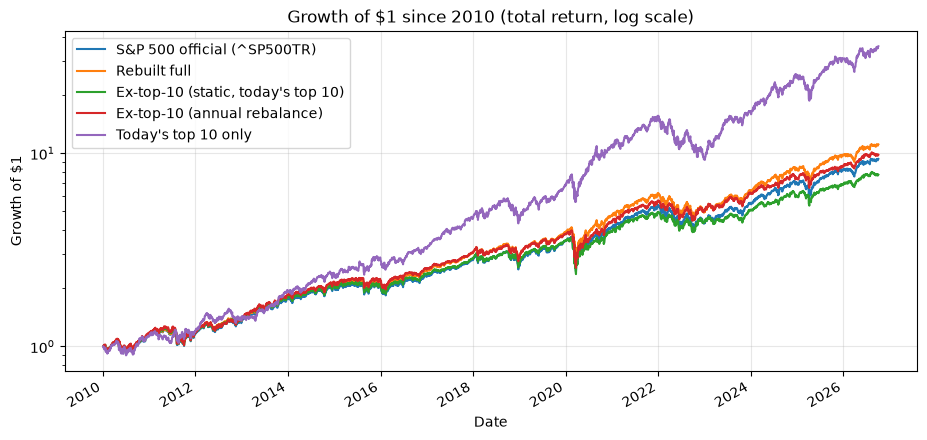

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
rebuilt.plot(ax=ax, logy=True)
ax.set_title("Growth of $1 since 2010 (total return, log scale)")
ax.set_ylabel("Growth of $1"); ax.grid(alpha=.3); plt.show()

## Part 3 — Investing only in the top 10, re-picked every year

The strategy: on the first trading day of each year, buy the 10 largest S&P 500 companies (by estimated market cap), hold them for the year, then repeat. Dividends are reinvested. Taxes and trading costs are ignored.

Three ways to weight the 10 stocks:
- **Top 10, cap-weighted**: each stock weighted by its market cap, like a mega-cap index fund.
- **Top 10, equal-weighted**: 10% in each stock every January, left to drift during the year.
- **2010 top 10, never re-picked**: buy the 2010 top 10 once, equal-weighted, and never trade. Shows whether re-picking each year matters.

Benchmark: the **official S&P 500 total return index** (`^SP500TR`). The rebuilt full index is also shown, since it uses the same data and method as the strategies.

The picks come from *today's* constituent list, but a top-10 company rarely leaves the index. Every company in the yearly top-10 table above is still in the index today, so survivorship bias is much smaller here than in Part 2.

In [15]:
def buy_and_hold_equal(picks_by_period: dict) -> pd.Series:
    """Equal-weight the picks at each period start (day-1 close), hold without rebalancing
    until the next period start, then chain the periods together."""
    starts = sorted(picks_by_period)
    value, pieces = 1.0, []
    for i, d0 in enumerate(starts):
        d1 = starts[i + 1] if i + 1 < len(starts) else adj.index[-1]
        px = adj.loc[d0:d1, picks_by_period[d0]]
        growth = (px / px.iloc[0]).mean(axis=1) * value
        pieces.append(growth if i == 0 else growth.iloc[1:])
        value = growth.iloc[-1]
    return pd.concat(pieces)

year_starts = mcap.groupby(mcap.index.year).apply(lambda b: b.index[0])
picks = {d0: mcap.loc[d0].nlargest(10).index.tolist() for d0 in year_starts}
first_picks = picks[year_starts.iloc[0]]

strategies = pd.DataFrame({
    "S&P 500 (^SP500TR)": rebuilt["S&P 500 official (^SP500TR)"],
    "Top 10 cap-weighted": cap_weighted_index(~annual_mask),
    "Top 10 equal-weighted": buy_and_hold_equal(picks),
    "2010 top 10, never re-picked": buy_and_hold_equal({year_starts.iloc[0]: first_picks}),
    "Rebuilt full index": rebuilt["Rebuilt full"],
})
print("2010 top 10:", ", ".join(name_of[first_picks]))
turnover = pd.Series({y.year: len(set(picks[y]) - set(picks[p]))
                      for p, y in zip(year_starts.iloc[:-1], year_starts.iloc[1:])})
print(f"Average names replaced each January: {turnover.mean():.1f} of 10")

2010 top 10: ExxonMobil, Microsoft, Alphabet Inc., Johnson & Johnson, AT&T, Walmart, Apple Inc., Procter & Gamble, Berkshire Hathaway, Bank of America
Average names replaced each January: 1.4 of 10


In [16]:
def max_drawdown(s: pd.Series) -> float:
    return (s / s.cummax() - 1).min()

daily = strategies.pct_change().dropna()
bench = daily["S&P 500 (^SP500TR)"]
yearly = pd.DataFrame({c: calendar_returns(strategies[c]) for c in strategies})

stats = pd.DataFrame({
    "Annualized (CAGR)": strategies.apply(cagr),
    "Volatility (ann.)": daily.std() * np.sqrt(252),
    "Max drawdown": strategies.apply(max_drawdown),
    "Return / vol": strategies.apply(cagr) / (daily.std() * np.sqrt(252)),
    "Beta vs S&P": daily.apply(lambda s: s.cov(bench) / bench.var()),
    "Years beating S&P": yearly.apply(lambda s: f"{(s > yearly['S&P 500 (^SP500TR)']).sum()} / {len(s)}")
                                .where(lambda x: x.index != "S&P 500 (^SP500TR)", "—"),
    "$10,000 becomes": strategies.iloc[-1] * 10_000,
})
stats.style.format({"Annualized (CAGR)": "{:.2%}", "Volatility (ann.)": "{:.1%}", "Max drawdown": "{:.1%}",
                    "Return / vol": "{:.2f}", "Beta vs S&P": "{:.2f}", "$10,000 becomes": "${:,.0f}"})

,Annualized (CAGR),Volatility (ann.),Max drawdown,Return / vol,Beta vs S&P,Years beating S&P,"$10,000 becomes"
S&P 500 (^SP500TR),14.27%,17.2%,-33.8%,0.83,1.00,—,"$93,394"
Top 10 cap-weighted,17.27%,20.2%,-39.2%,0.85,1.07,11 / 17,"$144,138"
Top 10 equal-weighted,15.94%,19.1%,-36.5%,0.83,1.03,10 / 17,"$119,122"
"2010 top 10, never re-picked",16.85%,17.5%,-28.6%,0.96,0.93,12 / 17,"$135,777"
Rebuilt full index,15.46%,17.2%,-33.6%,0.90,1.00,14 / 17,"$111,136"


In [17]:
year_labels = [f"{y} (YTD)" if y == end_date.year else y for y in yearly.index]
yearly_cmp = yearly.drop(columns="Rebuilt full index").copy()
yearly_cmp["Cap-wtd − S&P"] = yearly_cmp["Top 10 cap-weighted"] - yearly_cmp["S&P 500 (^SP500TR)"]
yearly_cmp["Equal-wtd − S&P"] = yearly_cmp["Top 10 equal-weighted"] - yearly_cmp["S&P 500 (^SP500TR)"]
yearly_cmp.index = year_labels
yearly_cmp.style.format("{:.1%}").map(
    lambda v: "color: #008300" if v > 0 else "color: #e34948", subset=["Cap-wtd − S&P", "Equal-wtd − S&P"])

,S&P 500 (^SP500TR),Top 10 cap-weighted,Top 10 equal-weighted,"2010 top 10, never re-picked",Cap-wtd − S&P,Equal-wtd − S&P
2010,13.2%,6.5%,7.3%,7.3%,-6.7%,-5.9%
2011,2.1%,11.6%,11.1%,4.8%,9.5%,9.0%
2012,16.0%,13.2%,12.8%,18.1%,-2.8%,-3.2%
2013,32.4%,26.7%,28.6%,25.3%,-5.7%,-3.8%
2014,13.7%,12.7%,12.3%,16.0%,-1.0%,-1.4%
2015,1.4%,3.6%,3.6%,0.4%,2.2%,2.2%
2016,12.0%,12.1%,12.5%,16.4%,0.1%,0.5%
2017,21.8%,32.7%,31.3%,27.7%,10.9%,9.4%
2018,-4.4%,-0.3%,-2.7%,-2.6%,4.0%,1.7%
2019,31.5%,40.9%,38.0%,44.6%,9.4%,6.5%


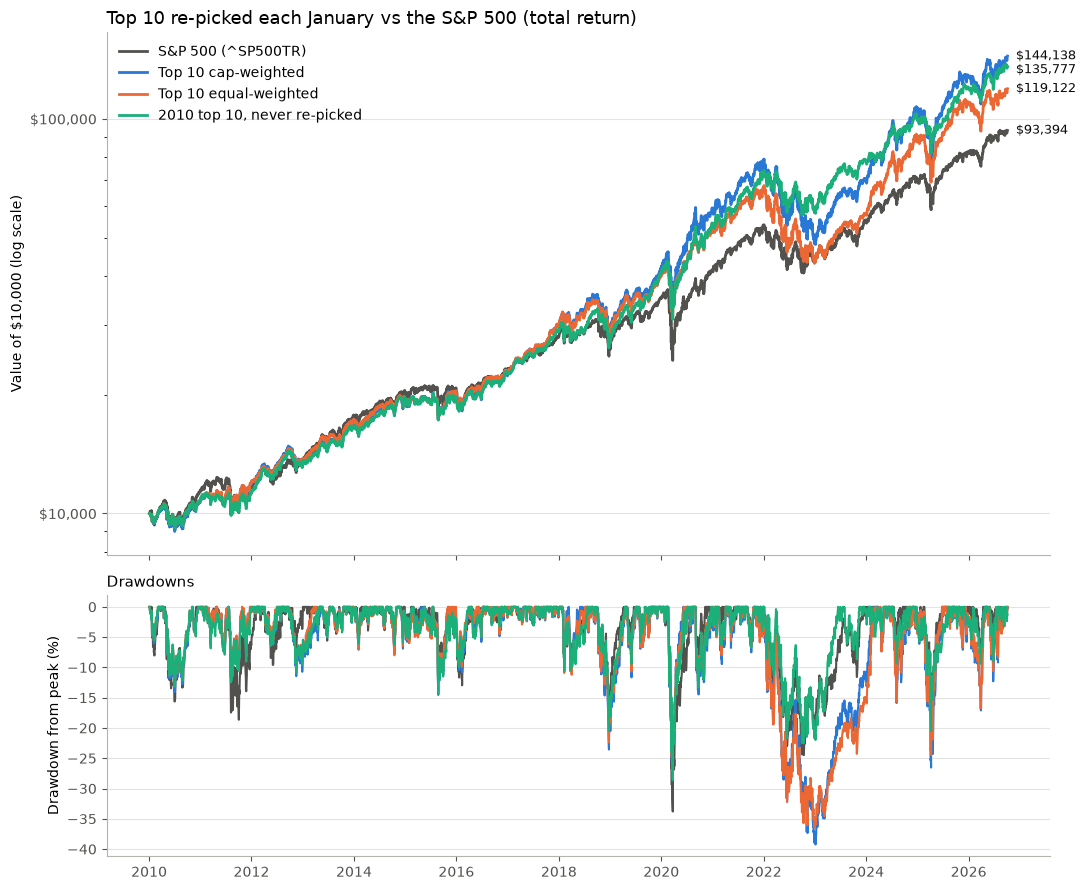

In [18]:
# Palette: validated categorical slots, in fixed order; same color = same strategy in every chart
COLORS = {
    "S&P 500 (^SP500TR)": "#52514e",            # neutral ink for the benchmark
    "Top 10 cap-weighted": "#2a78d6",           # slot 1 blue
    "Top 10 equal-weighted": "#eb6834",         # slot 2 orange
    "2010 top 10, never re-picked": "#1baf7a",  # slot 3 aqua
}
plot_cols = list(COLORS)

def style_axis(ax):
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    for side in ("left", "bottom"): ax.spines[side].set_color("#b5b3ad")
    ax.tick_params(colors="#52514e")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for c in plot_cols:
    s = strategies[c] * 10_000
    ax1.plot(s.index, s, color=COLORS[c], linewidth=2, label=c)
    dd = strategies[c] / strategies[c].cummax() - 1
    ax2.plot(dd.index, dd * 100, color=COLORS[c], linewidth=1.5)
# End labels, nudged apart (in log space) so close finishes don't collide
ends = sorted(((strategies[c].iloc[-1] * 10_000, c) for c in plot_cols), reverse=True)
label_y, min_gap = [], 0.035
for v, _ in ends:
    y = np.log10(v)
    label_y.append(min(y, label_y[-1] - min_gap) if label_y else y)
for (v, c), y in zip(ends, label_y):
    ax1.annotate(f"${v:,.0f}", (strategies.index[-1], 10 ** y), xytext=(6, 0),
                 textcoords="offset points", va="center", fontsize=9, color="#0b0b0b")
ax1.set_yscale("log"); ax1.set_ylabel("Value of $10,000 (log scale)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax1.set_title("Top 10 re-picked each January vs the S&P 500 (total return)", loc="left", fontsize=13)
ax1.legend(frameon=False, loc="upper left")
ax2.set_ylabel("Drawdown from peak (%)"); ax2.set_title("Drawdowns", loc="left", fontsize=11)
for ax in (ax1, ax2): style_axis(ax)
fig.tight_layout(); plt.show()

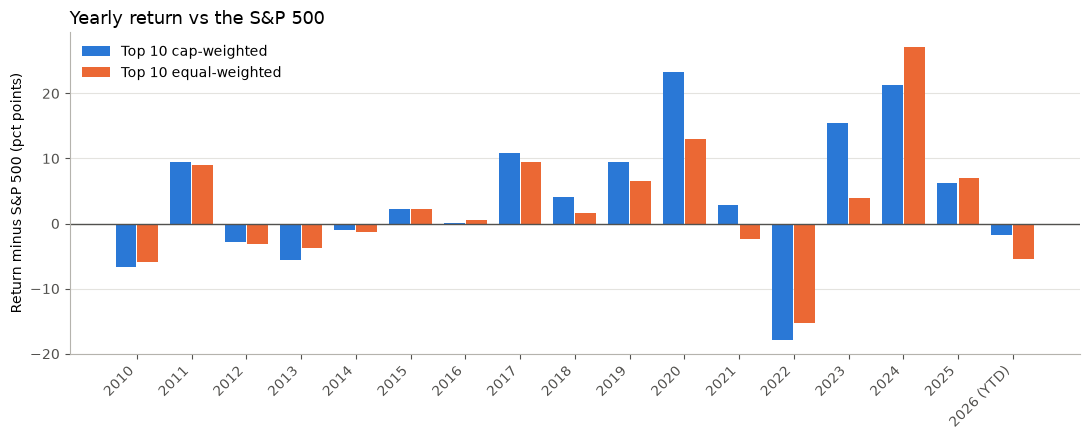

In [19]:
excess = yearly_cmp[["Cap-wtd − S&P", "Equal-wtd − S&P"]] * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(excess)); w = 0.38
ax.bar(x - w / 2 - 0.01, excess.iloc[:, 0], w, color=COLORS["Top 10 cap-weighted"], label="Top 10 cap-weighted")
ax.bar(x + w / 2 + 0.01, excess.iloc[:, 1], w, color=COLORS["Top 10 equal-weighted"], label="Top 10 equal-weighted")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xticks(x, [str(i) for i in excess.index], rotation=45, ha="right")
ax.set_ylabel("Return minus S&P 500 (pct points)")
ax.set_title("Yearly return vs the S&P 500", loc="left", fontsize=13)
ax.legend(frameon=False); style_axis(ax); fig.tight_layout(); plt.show()

In [20]:
# How performance splits across periods
periods = {"2010–2014": ("2010", "2014"), "2015–2019": ("2015", "2019"), "2020–now": ("2020", str(end_date.year))}
by_period = pd.DataFrame({
    p: strategies.loc[:b].iloc[[-1]].squeeze() / strategies.loc[:str(int(a) - 1)].iloc[-1]
       if a != "2010" else strategies.loc[:b].iloc[-1]
    for p, (a, b) in periods.items()
}).T
yrs = {p: (strategies.loc[:b].index[-1] - (strategies.loc[:str(int(a) - 1)].index[-1] if a != "2010" else strategies.index[0])).days / 365.25
       for p, (a, b) in periods.items()}
(by_period.apply(lambda r: r ** (1 / yrs[r.name]) - 1, axis=1)[plot_cols]
 .style.format("{:.1%}").set_caption("Annualized return by period"))

,S&P 500 (^SP500TR),Top 10 cap-weighted,Top 10 equal-weighted,"2010 top 10, never re-picked"
2010–2014,15.1%,14.0%,14.2%,14.1%
2015–2019,11.7%,16.7%,15.5%,16.0%
2020–now,15.6%,20.2%,17.6%,19.6%


## Part 4 — Equal weight (RSP) vs cap weight (SPY): does the RSP/SPY ratio do what people claim?

**RSP** (Invesco S&P 500 Equal Weight ETF) holds the same ~500 stocks as **SPY** but gives each about 0.2%, rebalanced quarterly. The **RSP/SPY ratio** therefore tracks *the average stock vs the cap-weighted index*. Common claims about it:

1. **Rising ratio = broad, healthy participation; falling ratio = mega-caps doing the work.**
2. **A low or falling ratio exposes concentration in the top 7–10 stocks.**
3. **A falling or low ratio warns of a market correction.**
4. **A breakout in the ratio signals smaller S&P 500 companies taking the lead.**

Each claim is tested below. Prices are dividend-adjusted (total return), starting from RSP's launch in 2003 so the 2008 crisis is included.

In [21]:
etf = yf.download(["RSP", "SPY"], start="2003-01-01", auto_adjust=True, progress=False)["Close"].dropna()
ratio = etf["RSP"] / etf["SPY"]
spy = etf["SPY"]
since2010 = etf.loc[START:]
print(f"Data: {etf.index[0].date()} → {etf.index[-1].date()}")
print(f"Since 2010: RSP {cagr(since2010['RSP']):.2%}/yr vs SPY {cagr(since2010['SPY']):.2%}/yr")
print(f"Ratio peak: {ratio.idxmax().date()}; today it is {ratio.iloc[-1] / ratio.max() - 1:.1%} below the peak")
print(f"Share of days since 2003 with a lower ratio than today: {(ratio < ratio.iloc[-1]).mean():.2%}")

etf_yearly = etf.resample("YE").last().pct_change().dropna()
etf_yearly["RSP − SPY"] = etf_yearly["RSP"] - etf_yearly["SPY"]
etf_yearly.index = [f"{y} (YTD)" if y == etf.index[-1].year else y for y in etf_yearly.index.year]
etf_yearly.style.format("{:.1%}").map(lambda v: "color: #008300" if v > 0 else "color: #e34948", subset=["RSP − SPY"])

Data: 2003-05-01 → 2026-10-05
Since 2010: RSP 12.23%/yr vs SPY 14.15%/yr
Ratio peak: 2015-04-06; today it is -30.4% below the peak
Share of days since 2003 with a lower ratio than today: 0.03%


Ticker,RSP,SPY,RSP − SPY
2004,16.5%,10.7%,5.8%
2005,7.4%,4.8%,2.6%
2006,15.5%,15.8%,-0.4%
2007,0.9%,5.1%,-4.2%
2008,-40.1%,-36.8%,-3.3%
2009,44.6%,26.4%,18.3%
2010,21.4%,15.1%,6.3%
2011,-0.7%,1.9%,-2.6%
2012,17.2%,16.0%,1.2%
2013,35.5%,32.3%,3.2%


### Claims 1 & 2 — does the ratio measure breadth and concentration?

Two measures from the constituent data in Part 2 (available from 2010):
- **Breadth**: % of S&P 500 stocks trading above their 200-day moving average.
- **Concentration**: combined weight of the 10 largest companies (estimated).

In [22]:
top10_weight = mcap.apply(lambda row: row.nlargest(10).sum(), axis=1) / mcap.sum(axis=1)
pct_above_200 = (adj[tickers] > adj[tickers].rolling(200).mean()).where(adj[tickers].notna()).mean(axis=1)

m = pd.DataFrame({
    "ratio": ratio.reindex(mcap.index),
    "top10_weight": top10_weight,
    "pct_above_200dma": pct_above_200,
}).resample("ME").last().loc["2011":]          # skip the 200-day warm-up
chg = m.diff(3).dropna()                        # 3-month changes
pd.DataFrame({
    "Correlation": [
        m["ratio"].corr(m["top10_weight"]),
        chg["ratio"].corr(chg["top10_weight"]),
        chg["ratio"].corr(chg["pct_above_200dma"]),
    ]}, index=[
        "Ratio level vs top-10 weight (monthly)",
        "3-month ratio change vs 3-month change in top-10 weight",
        "3-month ratio change vs 3-month change in % of stocks above 200-day MA",
    ]).style.format("{:+.2f}")

,Correlation
Ratio level vs top-10 weight (monthly),-0.98
3-month ratio change vs 3-month change in top-10 weight,-0.86
3-month ratio change vs 3-month change in % of stocks above 200-day MA,+0.33


In [23]:
# A rising ratio is not the same as a healthy market: years when the ratio and the market moved in opposite directions
mismatch = etf_yearly[(etf_yearly["RSP − SPY"] > 0) != (etf_yearly["SPY"] > 0)]
mismatch.style.format("{:.1%}")

Ticker,RSP,SPY,RSP − SPY
2006,15.5%,15.8%,-0.4%
2007,0.9%,5.1%,-4.2%
2011,-0.7%,1.9%,-2.6%
2015,-2.7%,1.2%,-3.9%
2017,18.5%,21.7%,-3.2%
2019,28.9%,31.2%,-2.3%
2020,12.7%,18.3%,-5.7%
2022,-11.6%,-18.2%,6.6%
2023,13.7%,26.2%,-12.5%
2024,12.8%,24.9%,-12.1%


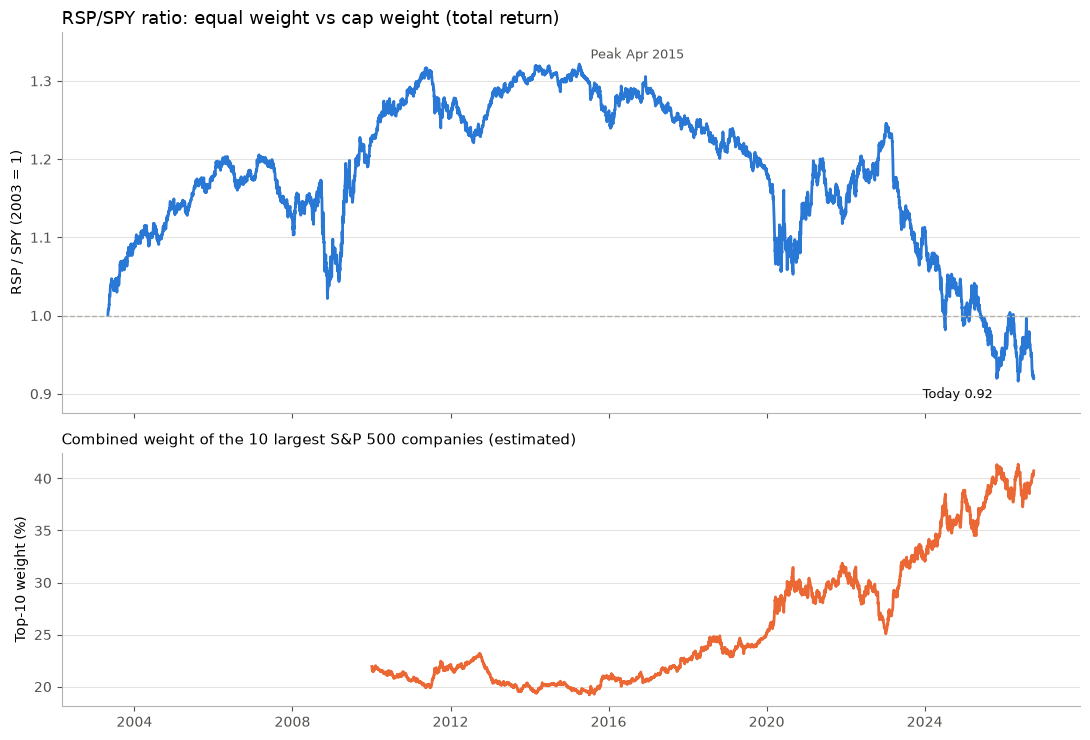

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
r_norm = ratio / ratio.iloc[0]
ax1.plot(r_norm.index, r_norm, color="#2a78d6", linewidth=2)
ax1.axhline(1, color="#b5b3ad", linewidth=1, linestyle="--")
ax1.annotate(f"Peak {ratio.idxmax():%b %Y}", (r_norm.idxmax(), r_norm.max()), xytext=(8, 4),
             textcoords="offset points", fontsize=9, color="#52514e")
ax1.annotate(f"Today {r_norm.iloc[-1]:.2f}", (r_norm.index[-1], r_norm.iloc[-1]), xytext=(-80, -14),
             textcoords="offset points", fontsize=9, color="#0b0b0b")
ax1.margins(y=0.1); ax1.set_ylabel("RSP / SPY (2003 = 1)")
ax1.set_title("RSP/SPY ratio: equal weight vs cap weight (total return)", loc="left", fontsize=13)
ax2.plot(top10_weight.index, top10_weight * 100, color="#eb6834", linewidth=2)
ax2.set_ylabel("Top-10 weight (%)")
ax2.set_title("Combined weight of the 10 largest S&P 500 companies (estimated)", loc="left", fontsize=11)
for ax in (ax1, ax2): style_axis(ax)
fig.tight_layout(); plt.show()

### Claim 3 — does a weak ratio warn of a correction?

For every trading day, look at what SPY did **next**: its return over the following 1, 3, 6 and 12 months, its average worst drop from peak over the next 6 months, and the chance that drop exceeded 10%. Compare days when the ratio looked weak or strong against all days.

The forward windows overlap, so the real number of independent episodes is much smaller than the day counts suggest. The robustness table that follows splits the history into periods.

In [25]:
horizons = {"1m": 21, "3m": 63, "6m": 126, "12m": 252}
fwd = {k: spy.shift(-h) / spy - 1 for k, h in horizons.items()}
spy_v = spy.values
fwd_dd = pd.Series([(spy_v[i:i + 127] / np.maximum.accumulate(spy_v[i:i + 127]) - 1).min()
                    if i + 126 < len(spy_v) else np.nan for i in range(len(spy_v))], index=spy.index)

chg6m = ratio / ratio.shift(126) - 1
signals = {
    "All days": pd.Series(True, index=ratio.index),
    "Ratio fell most over 6m (bottom 20%)": chg6m.rank(pct=True) <= 0.2,
    "Ratio rose most over 6m (top 20%)": chg6m.rank(pct=True) >= 0.8,
    "Ratio at a 52-week low": ratio <= ratio.rolling(252).min(),
    "Ratio below its 200-day average": ratio < ratio.rolling(200).mean(),
    "Ratio above its 200-day average": ratio > ratio.rolling(200).mean(),
}
usable = ratio.rolling(252).min().notna() & fwd_dd.notna()

def signal_stats(mask):
    mask = mask & usable
    return {"Days": int(mask.sum()),
            **{f"SPY next {k}": fwd[k][mask].mean() for k in horizons},
            "Avg worst drop, next 6m": fwd_dd[mask].mean(),
            "P(drop > 10%, next 6m)": (fwd_dd[mask] < -0.10).mean()}

signal_table = pd.DataFrame({k: signal_stats(v) for k, v in signals.items()}).T
signal_table.style.format("{:.1%}").format("{:,.0f}", subset=["Days"])

,Days,SPY next 1m,SPY next 3m,SPY next 6m,SPY next 12m,"Avg worst drop, next 6m","P(drop > 10%, next 6m)"
All days,"5,518",1.0%,2.9%,6.0%,12.2%,-10.2%,30.2%
Ratio fell most over 6m (bottom 20%),"1,124",1.1%,3.4%,8.6%,17.5%,-12.0%,38.6%
Ratio rose most over 6m (top 20%),"1,020",1.0%,3.6%,7.8%,14.3%,-8.6%,22.2%
Ratio at a 52-week low,252,0.5%,2.1%,7.2%,15.2%,-12.7%,44.4%
Ratio below its 200-day average,"2,872",1.0%,3.0%,6.3%,12.8%,-11.4%,38.2%
Ratio above its 200-day average,"2,646",0.9%,2.9%,5.7%,11.5%,-8.9%,21.5%


In [26]:
weak = signals["Ratio fell most over 6m (bottom 20%)"]
splits = {
    "2004–2009 (includes 2008)": (spy.index >= "2004") & (spy.index < "2010"),
    "2010–2019": (spy.index >= "2010") & (spy.index < "2020"),
    "2020–now": spy.index >= "2020",
    "Whole history minus 2007–2009": ~((spy.index >= "2007") & (spy.index < "2010")),
}
rows = {}
for name, period in splits.items():
    base = usable & period
    w = base & weak
    rows[name] = {
        "Weak-ratio days": int(w.sum()),
        "SPY next 12m: all days": fwd["12m"][base].mean(), "SPY next 12m: weak ratio": fwd["12m"][w].mean(),
        "P(drop>10%): all days": (fwd_dd[base] < -.1).mean(), "P(drop>10%): weak ratio": (fwd_dd[w] < -.1).mean(),
    }
pd.DataFrame(rows).T.style.format("{:.1%}").format("{:,.0f}", subset=["Weak-ratio days"])

,Weak-ratio days,SPY next 12m: all days,SPY next 12m: weak ratio,P(drop>10%): all days,P(drop>10%): weak ratio
2004–2009 (includes 2008),237,4.3%,3.0%,31.0%,86.9%
2010–2019,250,13.5%,17.4%,30.4%,36.4%
2020–now,637,17.7%,23.6%,29.2%,21.5%
Whole history minus 2007–2009,891,14.6%,21.7%,25.7%,25.6%


### Claim 4 — does a ratio breakout start a lasting leadership shift?

If breakouts start lasting trends, the ratio's past moves should predict its future moves. Two checks: autocorrelation of the ratio's monthly and quarterly changes, and how the ratio moved after reaching a 52-week high or crossing above its 200-day average.

In [27]:
fwd_ratio = {k: ratio.shift(-h) / ratio - 1 for k, h in {"3m": 63, "6m": 126, "12m": 252}.items()}
ma200 = ratio.rolling(200).mean()
cross_up = (ratio > ma200) & (ratio.shift(1) <= ma200.shift(1))
events = {
    "All days": usable,
    "Ratio at 52-week high": usable & (ratio >= ratio.rolling(252).max()),
    "Ratio crosses above 200-day average": usable & cross_up,
}
breakout = pd.DataFrame({k: {"Days": int(v.sum()), **{f"Ratio next {h}": s[v].mean() for h, s in fwd_ratio.items()},
                             "Share still higher after 6m": (fwd_ratio["6m"][v] > 0).mean()}
                         for k, v in events.items()}).T
print(f"Autocorrelation of ratio changes: monthly {ratio.resample('ME').last().pct_change().autocorr():+.2f}, "
      f"quarterly {ratio.resample('QE').last().pct_change().autocorr():+.2f}")
breakout.style.format("{:+.1%}").format("{:.0%}", subset=["Share still higher after 6m"]).format("{:,.0f}", subset=["Days"])

Autocorrelation of ratio changes: monthly +0.11, quarterly +0.06


,Days,Ratio next 3m,Ratio next 6m,Ratio next 12m,Share still higher after 6m
All days,"5,518",-0.1%,-0.3%,-0.6%,47%
Ratio at 52-week high,198,-0.3%,-0.6%,-0.1%,62%
Ratio crosses above 200-day average,73,-0.2%,-0.6%,-0.2%,38%


### Verdict on the RSP/SPY statement

| Claim | Verdict | Evidence |
|---|---|---|
| Rising ratio = broad, healthy participation; falling = mega-caps lead | **Half true** | The ratio does measure *the average stock vs the giants*. But "healthy" doesn't follow: the ratio rose in 2009 and 2022, both crashes or rebounds from one. It is also only loosely tied to actual breadth (correlation +0.33 with changes in the % of stocks above their 200-day average). |
| Exposes concentration in the top 7–10 | **True** | The ratio moves almost exactly opposite to the top-10 weight (−0.86 correlation in 3-month changes). It is a good concentration gauge, and it is at its lowest level since RSP launched while the top-10 weight is near its record. |
| Low or falling ratio warns of a correction | **Not supported** | The apparent warning comes almost entirely from 2007–09. Outside that period, the chance of a >10% drop after a weak ratio was the same as on any other day (≈26%), and SPY's next-12-month return was *higher* (21.7% vs 14.6%). The ratio has been falling since 2015, and the market kept going up. |
| A breakout signals a lasting leadership shift | **Weak at best** | Ratio changes barely persist (monthly autocorrelation +0.11, quarterly +0.06). After a 52-week high the ratio was still higher 6 months later 62% of the time, but on average it slipped. Crossing above the 200-day average predicted nothing. |

**Bottom line:** RSP/SPY is a useful *description* of how concentrated the market is, and right now it shows extreme concentration. It has not been a reliable *timing signal* for corrections or for rotations into smaller stocks. Owning RSP instead of SPY since 2010 cost about 1.9 points a year (12.2% vs 14.2%).

### Caveats
- **Survivorship bias**: only *today's* constituents are included, so companies that dropped out or went bankrupt since 2010 are missing. This pushes up the rebuilt returns. Compare "Rebuilt full" with the official `^SP500TR` to see how large the effect is.
- **Market-cap estimates**: Yahoo's share-count history starts around 2015, so each company's earliest known count is carried back to 2010. Companies whose share count changed a lot before 2015 therefore get rough weights in 2010–2014. The official index also uses float-adjusted caps, which this method does not.
- **The static "today's top 10" choice builds in hindsight**: these companies are the largest *because* they rose the most. Removing them therefore understates what an investor could have gotten in real time. The annual-rebalance version avoids that.
- Because the biases above hit the rebuilt full index and the ex-top-10 indices alike, **the gap between them** is more reliable than any single level.